# Step 1b — Adaptive mean vs Otsu baseline

Result: `run_adaptive` from `src/adaptive_thresholding.py` (grayscale → height 1000 → σ=1 blur → ink if `I < local_mean − C`, block 33, C = 6), compared with `run_otsu` from `src/thresholding.py`. Spec: `Claude Chat Memory/Adaptive_Thresholding.md`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt

import src.adaptive_thresholding as at
from src.thresholding import run_otsu
print(f"Frozen: HEIGHT={at.HEIGHT}, STROKE_W={at.STROKE_W}, BLOCK={at.BLOCK}, C={at.C}")

Frozen: HEIGHT=1000, STROKE_W=4, BLOCK=33, C=6


In [2]:
# Test images: synthetic clean / uneven light + own photos
def synthetic(h=200, w=700, seed=0):
    img = np.full((h, w), 225, np.uint8)
    P = lambda *xy: np.array(xy, np.int32).reshape(-1, 1, 2)
    for pts in [P(40,60, 70,40, 80,150), P(130,100, 200,100), P(165,65, 165,135), P(340,85, 410,85),
                P(340,115, 410,115), P(450,60, 500,45, 520,80, 450,150, 530,150), P(570,50, 640,150), P(640,50, 570,150)]:
        cv2.polylines(img, [pts], False, 40, 4)                      # 1 + = 2 x
    cv2.ellipse(img, (270, 100), (35, 50), 0, 0, 360, 40, 4)          # 0
    return np.clip(img + np.random.default_rng(seed).normal(0, 8, img.shape), 0, 255).astype(np.uint8)

clean = synthetic()
uneven = np.clip(clean * np.linspace(1.0, 0.25, clean.shape[1]), 0, 255).astype(np.uint8)
inputs = {"synthetic clean": clean, "synthetic uneven light": uneven}
photo_dir = ROOT / "data" / "raw" / "photos"
inputs |= {p.stem: p for p in sorted(photo_dir.glob("*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
list(inputs)
height = lambda name: inputs[name].shape[0] if name.startswith("synthetic") else at.HEIGHT   # don't upscale synthetic
prepared = {name: at.prepare(src, height(name)) for name, src in inputs.items()}

## 1. Parameters

- Stroke width `w`: median ink-run length in ~20 random rows/cols of the Otsu mask (`estimate_stroke_width`).
- Noise `σ_n`: std of a blank paper patch of photo 1 → `C ≈ 2.5·σ_n`.

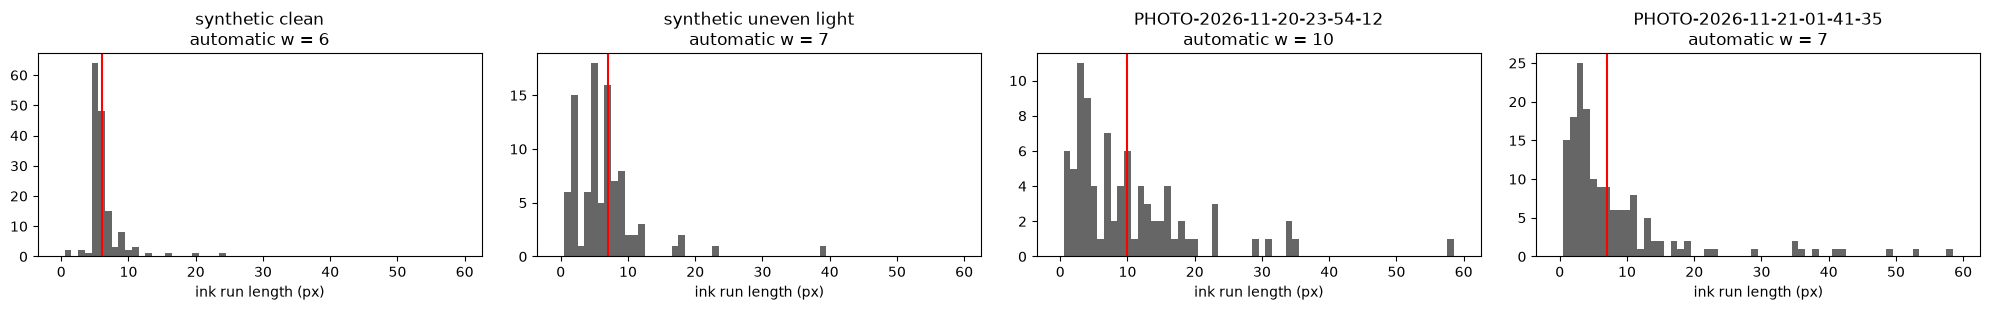

σ_n = 2.38 -> C0 ≈ 6.0


In [3]:
fig, ax = plt.subplots(1, len(prepared), figsize=(5 * len(prepared), 3.2))
for a, (name, gray) in zip(ax, prepared.items()):
    w, runs, *_ = at.estimate_stroke_width(gray, return_runs=True)
    a.hist(runs, bins=np.arange(0, 61) - 0.5, color="0.4"); a.axvline(w, color="r")
    a.set_title(f"{name}\nautomatic w = {w:g}"); a.set_xlabel("ink run length (px)")
plt.tight_layout(); plt.show()

photo = prepared[list(inputs)[2]]
print(f"σ_n = {np.std(photo[820:860, 900:940]):.2f} -> C0 ≈ {2.5 * np.std(photo[820:860, 900:940]):.1f}")

Automatic `w` is ≈ 6–7 on the synthetic images (true ≈ 5) but **10 on photo 1**, where by eye it is 4–5: Otsu fails on the photos, so its mask holds the page border, spiral holes and shadow rather than strokes. The frozen rule therefore uses the eye-checked `w = 4` → block 33, and `C = 6`.

## 2. Sweep on photo 1 (`block ∈ {5w, 8w, 12w}` × `C ∈ {C/2, C, 2C}`)

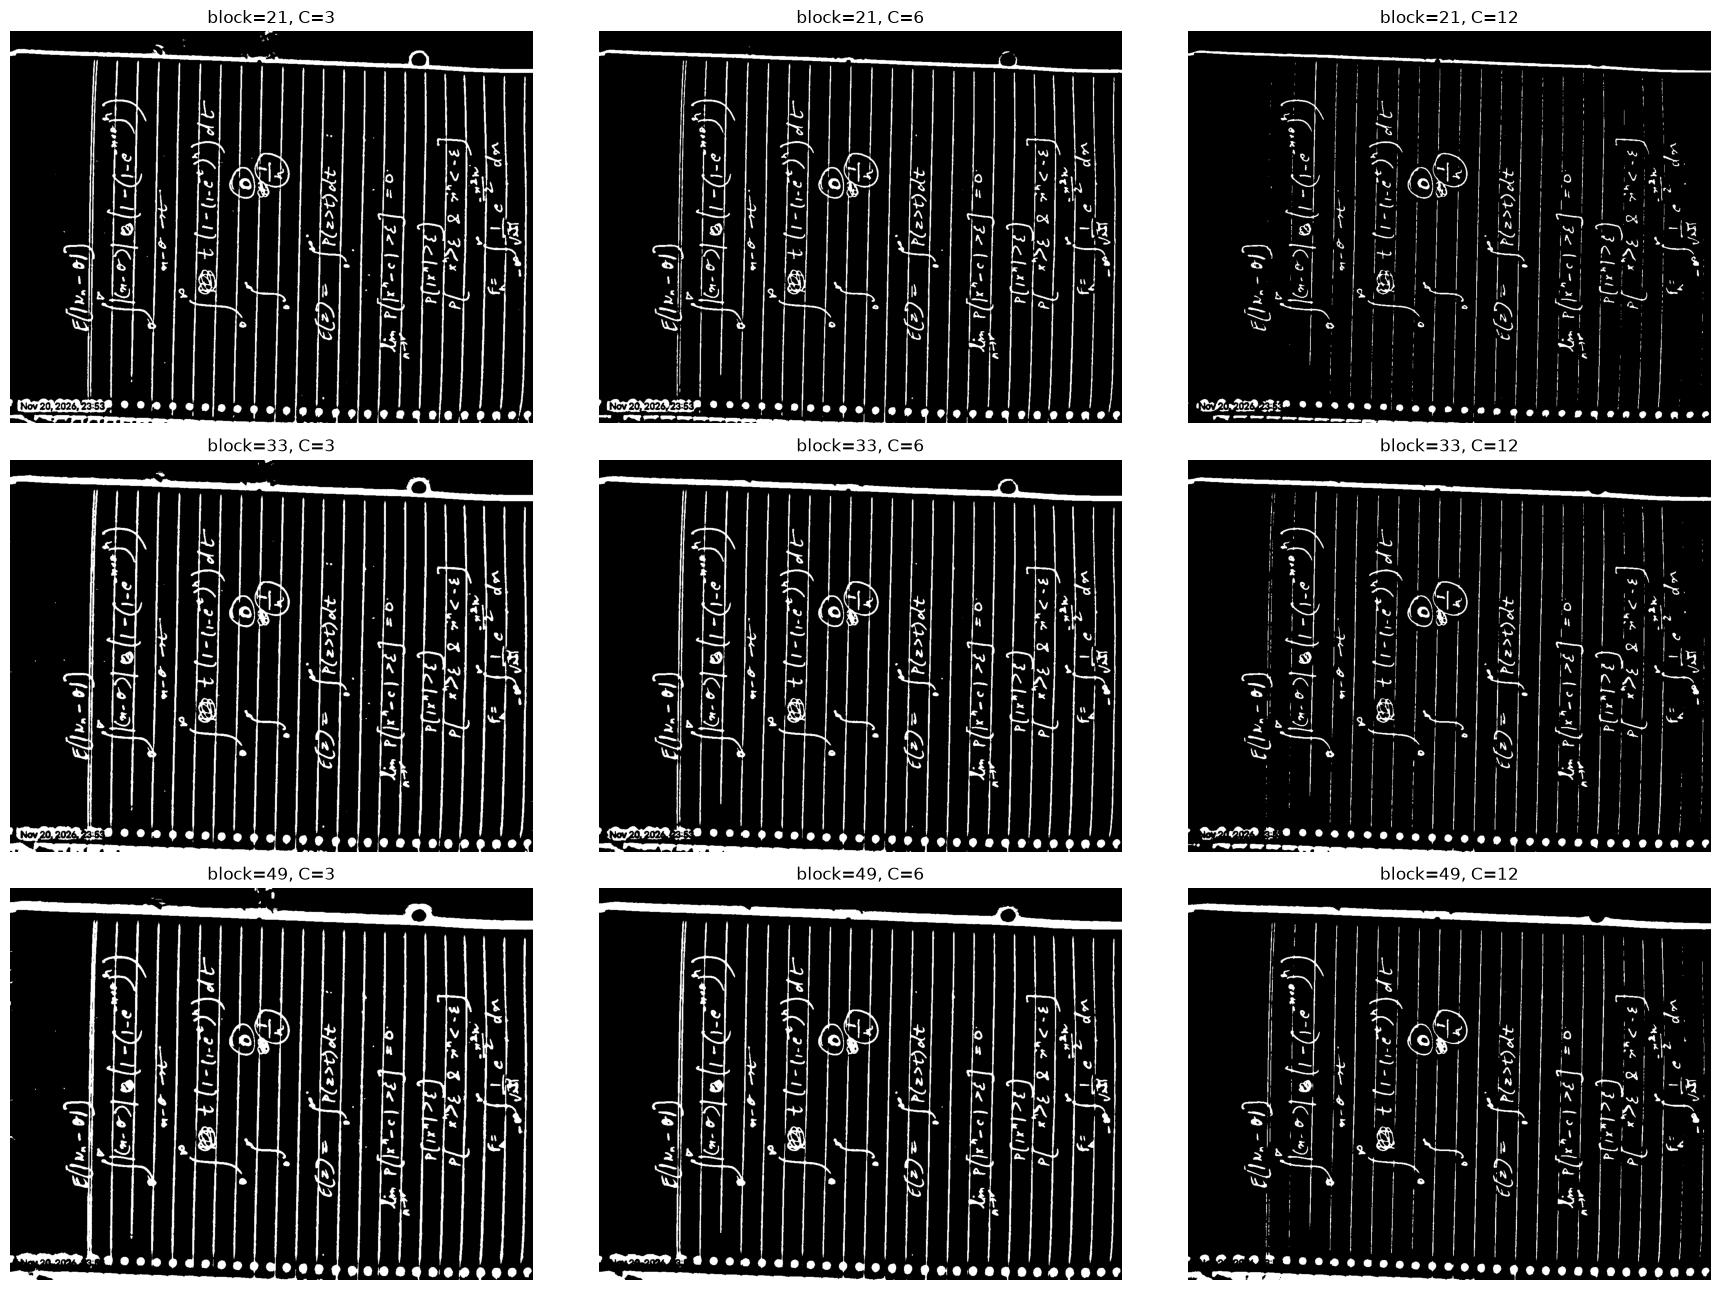

In [4]:
fig, ax = plt.subplots(3, 3, figsize=(18, 13))
for i, b in enumerate(at.odd(k * at.STROKE_W) for k in (5, 8, 12)):
    for j, c in enumerate((at.C / 2, at.C, 2 * at.C)):
        ax[i, j].imshow(at.adaptive_mean(photo, b, c)[0], cmap="gray")
        ax[i, j].set_title(f"block={b}, C={c:g}"); ax[i, j].axis("off")
plt.tight_layout(); plt.show()

## 3. `run_adaptive` vs `run_otsu`

Diff map: white = ink in both, green = adaptive only, red = Otsu only (Otsu output resized to the adaptive size only for this map).

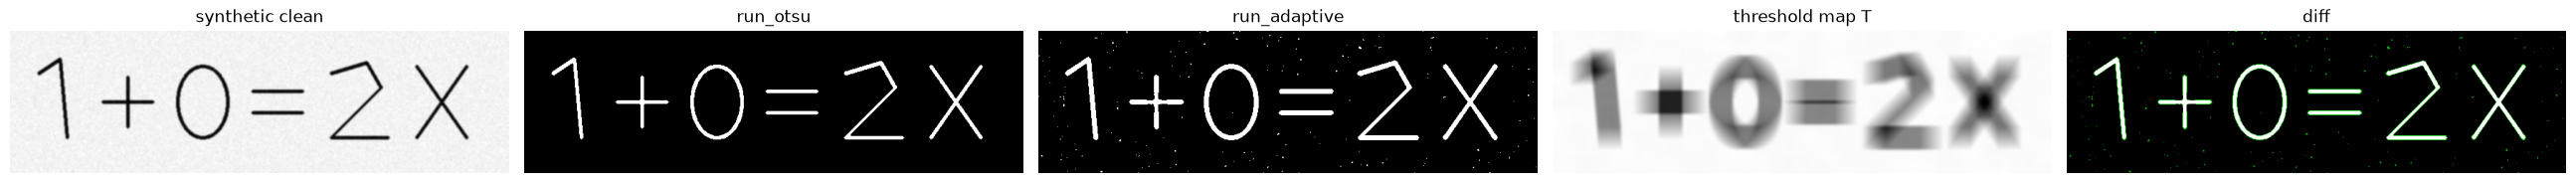

synthetic clean: ink % Otsu = 4.4, adaptive = 6.0, adaptive-only = 1.6, Otsu-only = 0.0


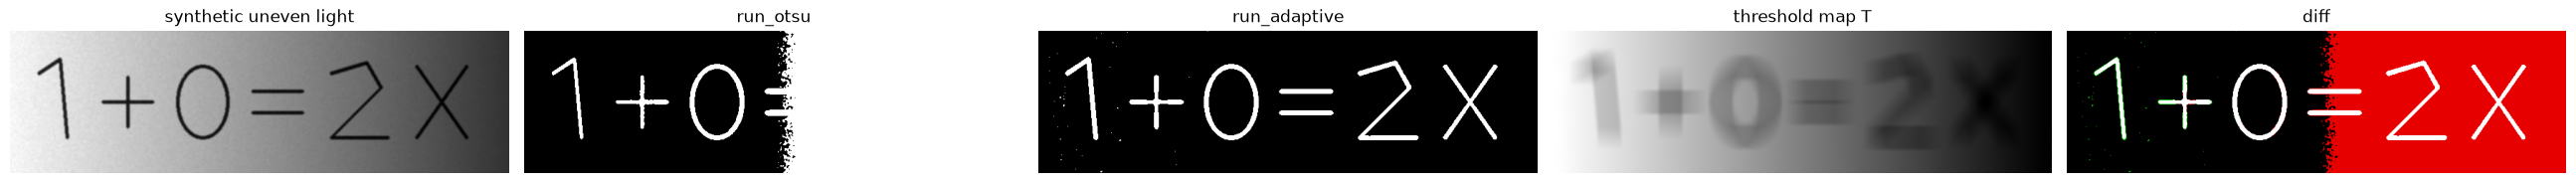

synthetic uneven light: ink % Otsu = 50.4, adaptive = 5.7, adaptive-only = 0.3, Otsu-only = 45.0


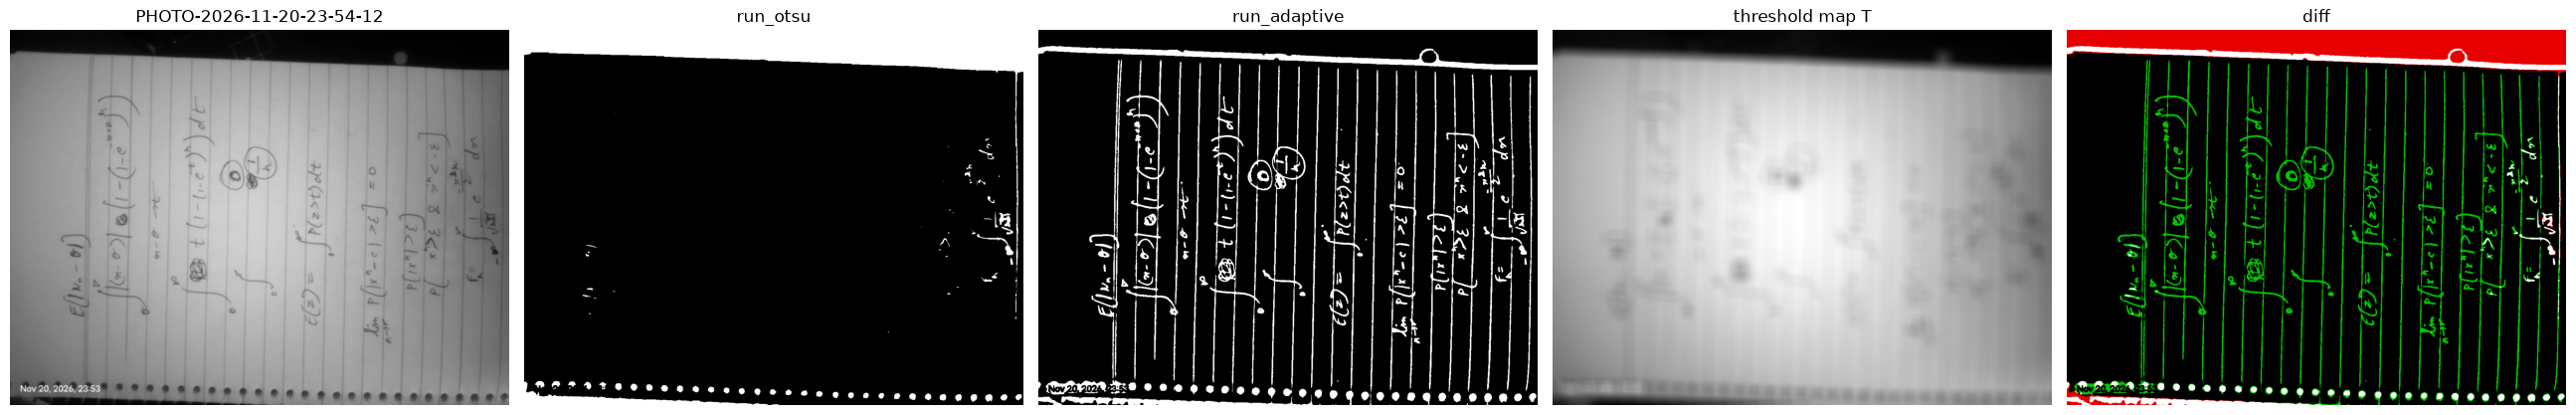

PHOTO-2026-11-20-23-54-12: ink % Otsu = 10.0, adaptive = 11.2, adaptive-only = 8.2, Otsu-only = 7.0


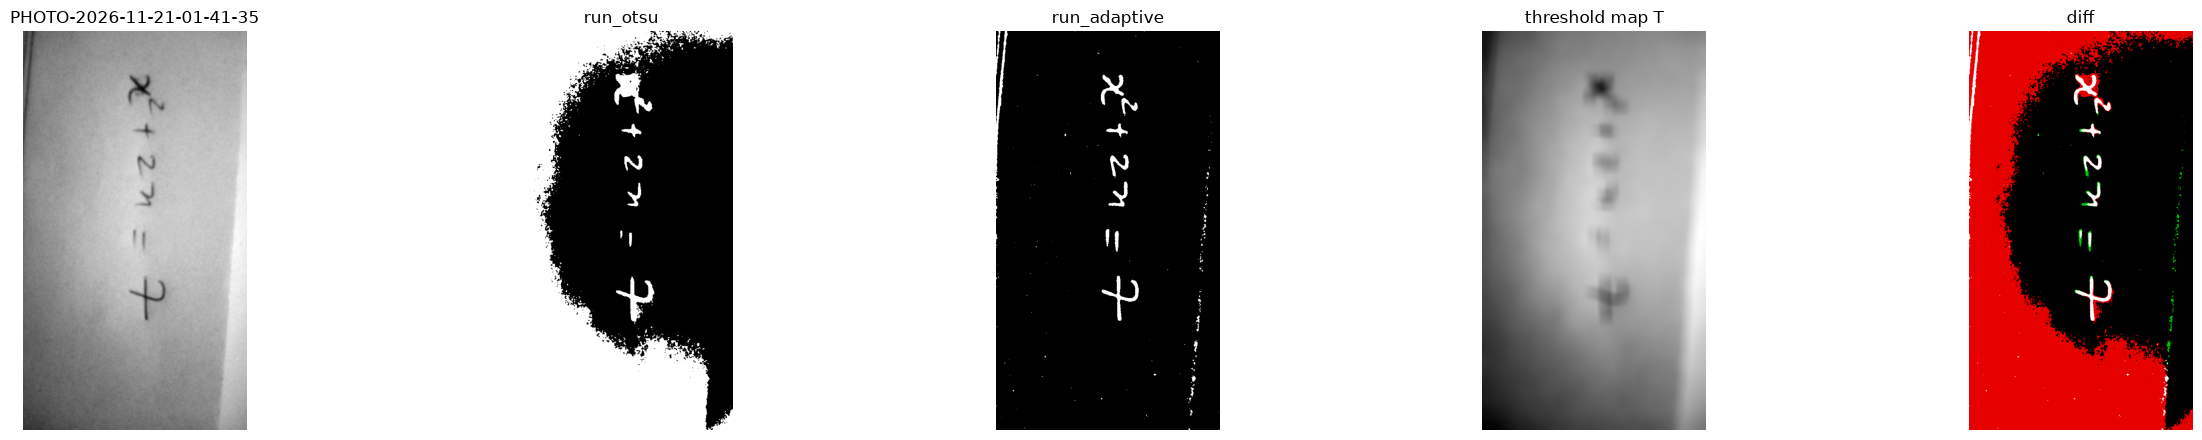

PHOTO-2026-11-21-01-41-35: ink % Otsu = 43.3, adaptive = 2.1, adaptive-only = 0.4, Otsu-only = 41.6


In [5]:
for name, src in inputs.items():
    adapt = at.run_adaptive(src, height(name))
    otsu = cv2.resize(run_otsu(src), adapt.shape[::-1], interpolation=cv2.INTER_NEAREST)
    diff = np.zeros(adapt.shape + (3,), np.uint8)
    diff[(adapt > 0) & (otsu > 0)] = 255
    diff[(adapt > 0) & (otsu == 0)] = (0, 200, 0)
    diff[(otsu > 0) & (adapt == 0)] = (230, 0, 0)

    panels = {name: prepared[name], "run_otsu": otsu, "run_adaptive": adapt,
              "threshold map T": at.adaptive_mean(prepared[name])[1], "diff": diff}
    fig, ax = plt.subplots(1, 5, figsize=(26, 4.5))
    for a, (title, im) in zip(ax, panels.items()):
        a.imshow(im, cmap="gray"); a.set_title(title); a.axis("off")
    plt.tight_layout(); plt.show()
    print(f"{name}: ink % Otsu = {100 * (otsu > 0).mean():.1f}, adaptive = {100 * (adapt > 0).mean():.1f}, "
          f"adaptive-only = {100 * (diff[..., 1] == 200).mean():.1f}, Otsu-only = {100 * (diff[..., 0] == 230).mean():.1f}")

## 4. Observations

| Image | `run_otsu` | `run_adaptive` |
|---|---|---|
| Synthetic clean | clean strokes | correct, slightly thicker strokes, fine speckle on blank paper (Otsu slightly better) |
| Synthetic uneven light | dark right side becomes ink, `=2x` lost | all symbols recovered |
| Photo 1 (dim, lined) | t* set by the dark background; writing lost | writing recovered, incl. faint strokes |
| Photo 2 (`x²+2x=7`, shadow) | shadowed left half becomes ink | clean expression, only a thin paper edge and a few specks |

- Sweep: C = 12 breaks faint strokes; C = 3 thickens strokes and adds edge junk; no hollow strokes for block ≥ 21.
- Not solved by thresholding: ruled lines, spiral holes, page edges, timestamp (need a later step).
- Parameters are tuned on one photo only.